# GTEx simulation cases with SuSiE-inf (data processing)

Simulated examples for SuSiE-inf with and without the R-uncertainty adjustment, next to the UKB cases (`Data_Processing/Figure_5/UKB_SuSiE_inf_Cases`). GTEx eQTL simulation of Fig 3A (`09` `[finemap]`, `Gtex_fine/result/`), 3 causal variants. Three regions with ADSP LD and three with 1000 Genomes LD where SuSiE-rRSS (pipeline: SER model when flagged) and SuSiE-RSS give a different number of credible sets and SuSiE-rRSS has the lower FDR.

1. **Select** from the per-region table of `10` `[susie_bias_summary]` (stored fits): every h2g, 3 causal. FDR = 1 − (credible sets containing a causal variant) / (credible sets). Up to 5 candidates per reference, the largest FDR drop first, spread over h2g.
2. **Refit** each candidate with the GitHub version of susieR (`stephenslab/susieR`), on the same inputs as `09`: in-sample SuSiE and SuSiE-inf, and with the reference LD SuSiE-RSS, SuSiE-rRSS, SuSiE-inf and SuSiE-inf + rRSS (`R_finite` = 10,000 for ADSP and 489 for 1000 Genomes, `R_mismatch = "eb_mix"`, as in `09`).
3. **Keep** the first 3 candidates per reference whose refit reproduces the selection: SuSiE-rRSS and SuSiE-RSS still differ in CS number and SuSiE-rRSS still has the lower FDR.

SuSiE-inf needs the p × p reference R. Upstream `add_eigen_decomposition()` fails on a low-rank X (B < p), so for the ADSP sketch R is passed when B < p.

**Outputs:**
- `figure_data/GTEx_SuSiE_inf_Cases_Candidates.rds` (+ csv): one row per candidate: stored and refit CS numbers and FDR, `reproduced`, `shown`
- `figure_data/GTEx_SuSiE_inf_Cases_Summary.rds` (+ csv): one row per candidate × method: credible sets (true), FDR, causal variants found, τ², flag, Q_art, D_CS,max (after the SER fallback where flagged)
- `figure_data/GTEx_SuSiE_inf_Cases_PIP.rds` (+ csv): one row per candidate × method × variant: PIP and credible set, before and after the SER fallback
- `figure_data/GTEx_SuSiE_inf_Cases_Variants.rds` (+ csv): one row per candidate × variant: z, −log10 p, causal, lead
- `figure_data/GTEx_SuSiE_inf_Example_kg4_{Summary,PIP,Variants,Case}.rds` (+ csv): the kg_4 case alone, refitted on its own (section 4), for `Figures/Figure_3/GTEx_SuSiE_inf_Example_kg4`

In [2]:
library(tidyverse)
library(MASS)
library(Matrix)
library(crayon)
library(Rfast)
library(matrixStats)
library(mixsqp)
library(reshape)

## susieR from GitHub, in its own environment. Clone once (as for UKB_SuSiE_inf_Cases):
##   git clone https://github.com/stephenslab/susieR.git /sc/arion/projects/ad-omics/haochen/rss_qc/susieR_stephenslab
susie_up_dir <- "/sc/arion/projects/ad-omics/haochen/rss_qc/susieR"
system(sprintf("git -C %s log -1 --format='susieR %%h %%cd %%s'", susie_up_dir))
source_build <- function(dir) {
  env <- new.env(parent = globalenv())
  for (f in list.files(dir, pattern = "\\.R$", full.names = TRUE)) sys.source(f, envir = env)
  env
}
up <- source_build(file.path(susie_up_dir, "R"))

## repo helpers last, so nothing from the sourced build shadows them
source("../../R/utils.R")

summ_all <- readRDS("/hpc/users/sunh17/haochen/rss_qc/2026_output/Gtex_fine/summary/result_susie_bias_summary_summary.rds")
refs   <- c("ADSP", "kg")
n_cand <- 5           # candidates refitted per reference
n_show <- 3           # shown per reference

## 1. Select

In [3]:
## ---- candidates: 3 causal, SuSiE-rRSS (pipeline) and SuSiE-RSS differ in CS number, lower FDR ----
## rows of notebook 10 [susie_bias_summary]: "<ref>" = SuSiE-RSS, "<ref>_mix" = eb_mix fit (flag),
## "<ref>_mix_SER" = its SER model; SuSiE-rRSS = the SER model when the flag is set (pipeline)
fdr <- function(true_cs, n_cs) if_else(n_cs > 0, 1 - true_cs / n_cs, NA_real_)
per_ref <- function(ref) {
  rows <- summ_all %>% filter(ncausal == 3, method %in% paste0(ref, c("", "_mix", "_mix_SER"))) %>%
    mutate(kind = recode(method, !!ref := "rss", !!paste0(ref, "_mix") := "mix", !!paste0(ref, "_mix_SER") := "ser")) %>%
    select(input_file, kind, n_cs = total_set_number, true_cs = true_set_number, causal_found = true_var_number,
           flag = R_reliability_flag, Q_art, D_CS_max) %>%
    distinct(input_file, kind, .keep_all = TRUE)
  rss <- filter(rows, kind == "rss"); mix <- filter(rows, kind == "mix"); ser <- filter(rows, kind == "ser")
  mix %>% select(input_file, flag, Q_art, D_CS_max, n_cs_mix = n_cs, true_cs_mix = true_cs) %>%
    left_join(select(ser, input_file, n_cs_ser = n_cs, true_cs_ser = true_cs), by = "input_file") %>%
    mutate(fallback = flag %in% TRUE,
           n_cs_rrss   = if_else(fallback, n_cs_ser, n_cs_mix),
           true_cs_rrss = if_else(fallback, true_cs_ser, true_cs_mix)) %>%
    inner_join(select(rss, input_file, n_cs_rss = n_cs, true_cs_rss = true_cs), by = "input_file") %>%
    transmute(ref, input_file, h2g = as.numeric(str_match(input_file, "h2g_([0-9.]+)")[, 2]),
              sample = str_match(basename(input_file), "^sample_([0-9]+)")[, 2],
              n_cs_rss, true_cs_rss, fdr_rss = fdr(true_cs_rss, n_cs_rss),
              n_cs_rrss, true_cs_rrss, fdr_rrss = fdr(true_cs_rrss, n_cs_rrss),
              fallback, Q_art, D_CS_max)
}
pairs <- map_dfr(refs, per_ref)
pairs <- pairs %>%
  mutate(cs_number_differs = n_cs_rrss != n_cs_rss,
         eligible = cs_number_differs & n_cs_rrss >= 1 & n_cs_rss >= 1 & fdr_rrss < fdr_rss)
pairs %>% group_by(ref) %>%
  summarise(regions = n(), cs_number_differs = sum(cs_number_differs), eligible = sum(eligible), .groups = "drop") %>%
  as.data.frame()

## candidates per reference: largest FDR drop first, then the larger CS-number change; spread over h2g
cand <- pairs %>% filter(eligible) %>%
  mutate(fdr_drop = fdr_rss - fdr_rrss) %>%
  arrange(ref, desc(fdr_drop), desc(abs(n_cs_rss - n_cs_rrss)), desc(h2g)) %>%
  group_by(ref, h2g) %>% mutate(within_h2g = row_number()) %>%
  group_by(ref) %>% arrange(within_h2g, desc(fdr_drop), .by_group = TRUE) %>%
  slice_head(n = n_cand) %>% mutate(rank = row_number(), case = sprintf("%s_%d", ref, rank)) %>% ungroup()
cand %>% select(case, h2g, sample, n_cs_rss, fdr_rss, n_cs_rrss, fdr_rrss, fallback) %>%
  mutate(across(where(is.double), ~ signif(.x, 3))) %>% as.data.frame()

ref,regions,cs_number_differs,eligible
<chr>,<int>,<int>,<int>
ADSP,2400,265,153
kg,2400,829,457


case,h2g,sample,n_cs_rss,fdr_rss,n_cs_rrss,fdr_rrss,fallback
<chr>,<dbl>,<chr>,<int>,<dbl>,<int>,<dbl>,<lgl>
ADSP_1,0.03,99,2,1.000,1,0,FALSE
ADSP_2,0.15,23,10,0.900,1,0,TRUE
ADSP_3,0.10,220,10,0.900,3,0,FALSE
ADSP_4,0.05,316,3,0.667,2,0,FALSE
ADSP_5,0.02,85,2,0.500,1,0,FALSE
kg_1,0.15,261,8,1.000,1,0,TRUE
kg_2,0.10,432,10,1.000,3,0,FALSE
kg_3,0.05,229,9,0.889,3,0,FALSE
kg_4,0.03,99,5,0.600,1,0,TRUE


## 2. Refit

In [4]:
## ---- refit one candidate: in-sample, SuSiE-RSS, SuSiE-rRSS, SuSiE-inf, SuSiE-inf + rRSS ----
method_labels <- c(insample = "In-sample SuSiE", insample_inf = "In-sample SuSiE-inf",
                   susie_rss = "SuSiE-RSS", susie_rrss = "SuSiE-rRSS",
                   susie_inf = "SuSiE-inf", susie_inf_rrss = "SuSiE-inf + rRSS")
B_ref <- c(ADSP = 10000, kg = 489)               # R_finite as in 09 [finemap]

cs_index <- function(fit, p) {
  cs <- rep(0L, p)
  for (k in seq_along(fit$sets$cs)) cs[fit$sets$cs[[k]]] <- k
  cs
}

fit_gtex_case <- function(case, ref, result_file) {
  res  <- readRDS(result_file)
  dat  <- readRDS(res$input_path)
  n    <- dat$n_samples
  causal <- dat$true_vars
  ## reference: ADSP sketch U (p x B, X = t(U)) or 1000G LD; susie-inf needs the p x p R when B < p
  if (ref == "ADSP") {
    z <- dat$ADSP_input$sumstat$z; X <- t(dat$ADSP_input$U)
    ref_args <- if (nrow(X) >= ncol(X)) list(X = X) else list(R = up$safe_cor(X))
  } else {
    z <- dat$kg_input$sumstat$z; ref_args <- list(R = dat$kg_input$LD)
  }
  p   <- length(z)
  adj <- list(R_finite = B_ref[[ref]], R_mismatch = "eb_mix")
  inf <- list(unmappable_effects = "inf")
  zi  <- dat$insample_input$sumstat$z; Ri <- dat$insample_input$LD

  run <- function(m, args) {
    t0  <- Sys.time()
    fit <- tryCatch(suppressWarnings(do.call(up$susie_rss, c(args, list(n = n)))),
                    error = function(e) { cat(sprintf("[FAIL] %s %s: %s\n", case, m, conditionMessage(e))); NULL })
    if (is.null(fit)) return(NULL)
    dg    <- fit$R_finite_diagnostics
    flag  <- isTRUE(dg$R_reliability_flag)
    final <- if (flag && !is.null(dg$ser_model)) dg$ser_model else fit      # pipeline result: SER model when flagged
    cs_f  <- final$sets$cs
    true_cs <- sum(map_lgl(cs_f, ~ any(causal %in% .x)))
    summ <- tibble(case = case, method = m, n_cs = length(fit$sets$cs), n_cs_final = length(cs_f),
                   true_cs_final = true_cs, fdr_final = if (length(cs_f)) 1 - true_cs / length(cs_f) else NA_real_,
                   causal_found = sum(causal %in% unlist(cs_f)),
                   tau2 = fit$tau2 %||% NA_real_, ser_fallback = flag, Q_art = dg$Q_art %||% NA_real_,
                   D_CS_max = if (length(dg$bf_attenuation$cs_max)) max(dg$bf_attenuation$cs_max) else NA_real_,
                   time_s = as.numeric(difftime(Sys.time(), t0, units = "secs")))
    cat(sprintf("%s %s: %d CS (%d true)%s, %.0f s\n", case, m, summ$n_cs_final, true_cs,
                if (flag) " after SER fallback" else "", summ$time_s))
    list(summ = summ,
         pip = tibble(case = case, method = m, idx = seq_len(p), pip = as.numeric(fit$pip), cs = cs_index(fit, p),
                      pip_final = as.numeric(final$pip), cs_final = cs_index(final, p)))
  }

  fits <- list(
    insample       = run("insample",       list(z = zi, R = Ri)),
    insample_inf   = run("insample_inf",   c(list(z = zi, R = Ri), inf)),
    susie_rss      = run("susie_rss",      c(list(z = z), ref_args)),
    susie_rrss     = run("susie_rrss",     c(list(z = z), ref_args, adj)),
    susie_inf      = run("susie_inf",      c(list(z = z), ref_args, inf)),
    susie_inf_rrss = run("susie_inf_rrss", c(list(z = z), ref_args, adj, inf))) %>% compact()

  vars <- tibble(case = case, ref = ref, result_file = result_file, idx = seq_len(p), z = z, z_insample = zi,
                 logp = -(pnorm(-abs(z), log.p = TRUE) + log(2)) / log(10),
                 causal = seq_len(p) %in% causal, lead = seq_len(p) == which.max(abs(z)))
  list(vars = vars, summ = map_dfr(fits, "summ"), pip = map_dfr(fits, "pip"))
}

In [8]:
res  <- pmap(list(cand$case, cand$ref, cand$input_file), fit_gtex_case)
vars <- map_dfr(res, "vars")
summ <- map_dfr(res, "summ")
pip  <- map_dfr(res, "pip")

summ %>% select(case, method, n_cs_final, true_cs_final, fdr_final, causal_found, tau2, ser_fallback) %>%
  mutate(across(where(is.double), ~ signif(.x, 3))) %>% as.data.frame()

HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.



ADSP_1 insample: 1 CS (1 true), 1 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.

HINT: Switching to PIP-based convergence: unmappable effects models (inf/ash) do not have a well-defined ELBO.

HINT: unmappable_effects = 'inf' requires estimate_residual_variance = TRUE to estimate the infinitesimal variance tau^2; overriding to TRUE.



ADSP_1 insample_inf: 1 CS (1 true), 7 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.




ADSP_1 susie_rss: 2 CS (0 true), 5 s


... (111 outputs left out)

kg_5 susie_inf: 10 CS (0 true), 10 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.

HINT: Switching to PIP-based convergence: R uncertainty inflation modifies per-variant SER likelihoods, which prevents a consistent model-level ELBO.

HINT: unmappable_effects = 'inf' requires estimate_residual_variance = TRUE to estimate the infinitesimal variance tau^2; overriding to TRUE.





kg_5 susie_inf_rrss: 0 CS (0 true) after SER fallback, 12 s


case,method,n_cs_final,true_cs_final,fdr_final,causal_found,tau2,ser_fallback
<chr>,<chr>,<int>,<int>,<dbl>,<int>,<dbl>,<lgl>
ADSP_1,insample,1,1,0.000,1,NA,FALSE
ADSP_1,insample_inf,1,1,0.000,1,2.79e-05,FALSE
ADSP_1,susie_rss,2,0,1.000,0,NA,FALSE
ADSP_1,susie_rrss,1,1,0.000,1,NA,FALSE
ADSP_2,insample,3,3,0.000,3,NA,FALSE
ADSP_2,insample_inf,3,3,0.000,3,0.00e+00,FALSE
ADSP_2,susie_rss,10,1,0.900,1,NA,FALSE
ADSP_2,susie_rrss,1,1,0.000,1,NA,TRUE
ADSP_2,susie_inf_rrss,3,2,0.333,2,1.19e-03,FALSE


## 3. Keep the reproduced cases

In [2]:
## keep the candidates whose refit reproduces the selection (SuSiE-rRSS and SuSiE-RSS differ in CS number,
## SuSiE-rRSS has the lower FDR), in candidate order, up to n_show per reference
refit <- summ %>% filter(method %in% c("susie_rss", "susie_rrss")) %>%
  select(case, method, n_cs_final, fdr_final) %>%
  pivot_wider(names_from = method, values_from = c(n_cs_final, fdr_final))
cand <- cand %>% left_join(refit, by = "case") %>%
  mutate(reproduced = n_cs_final_susie_rrss != n_cs_final_susie_rss & n_cs_final_susie_rrss >= 1 &
                      coalesce(fdr_final_susie_rrss < fdr_final_susie_rss, FALSE)) %>%
  group_by(ref) %>% arrange(!reproduced, rank, .by_group = TRUE) %>%
  mutate(shown = reproduced & cumsum(reproduced) <= n_show) %>% ungroup() %>% arrange(ref, rank)
cand %>% select(case, h2g, sample, n_cs_rss, fdr_rss, n_cs_rrss, fdr_rrss,
                n_cs_final_susie_rss, fdr_final_susie_rss, n_cs_final_susie_rrss, fdr_final_susie_rrss, reproduced, shown) %>%
  mutate(across(where(is.double), ~ signif(.x, 3))) %>% as.data.frame()

save_data(cand, "GTEx_SuSiE_inf_Cases_Candidates")
save_data(summ, "GTEx_SuSiE_inf_Cases_Summary")
save_data(pip,  "GTEx_SuSiE_inf_Cases_PIP")
save_data(vars, "GTEx_SuSiE_inf_Cases_Variants")

ERROR: Error: object 'summ' not found


## 4. Example: kg_4

1000 Genomes LD (`R_finite` = 489), 3 causal variants, h2g = 0.03, sample 99. SuSiE-RSS gives 5 credible sets (2 true) and SuSiE-inf 8 (0 true); SuSiE-rRSS (after SER fallback) and SuSiE-inf + rRSS (no fallback) give 1 true credible set, as in-sample SuSiE and SuSiE-inf.

Refits kg_4 alone (about a minute): run the setup (section 0), **1. Select** (defines `cand`) and the first cell of **2. Refit** (defines `fit_gtex_case`), then this cell; the refit of all candidates and section 3 can be skipped.

In [5]:
ex <- "kg_4"
ex_case <- filter(cand, case == ex)
stopifnot(nrow(ex_case) == 1, ex_case$ref == "kg", ex_case$h2g == 0.03, ex_case$sample == "99")   # the case shown above
ex_case %>% select(case, ref, h2g, sample, n_cs_rss, fdr_rss, n_cs_rrss, fdr_rrss, fallback, input_file) %>% as.data.frame()

ex_fit  <- fit_gtex_case(ex_case$case, ex_case$ref, ex_case$input_file)
ex_summ <- ex_fit$summ; ex_pip <- ex_fit$pip; ex_vars <- ex_fit$vars
ex_summ %>% select(case, method, n_cs, n_cs_final, true_cs_final, fdr_final, causal_found, tau2, ser_fallback, Q_art, D_CS_max) %>%
  mutate(across(where(is.double), ~ signif(.x, 3))) %>% as.data.frame()

save_data(ex_case, "GTEx_SuSiE_inf_Example_kg4_Case")
save_data(ex_summ, "GTEx_SuSiE_inf_Example_kg4_Summary")
save_data(ex_pip,  "GTEx_SuSiE_inf_Example_kg4_PIP")
save_data(ex_vars, "GTEx_SuSiE_inf_Example_kg4_Variants")

case,ref,h2g,sample,n_cs_rss,fdr_rss,n_cs_rrss,fdr_rrss,fallback,input_file
<chr>,<chr>,<dbl>,<chr>,<int>,<dbl>,<int>,<dbl>,<lgl>,<chr>
kg_4,kg,0.03,99,5,0.6,1,0,TRUE,/sc/arion/projects/ad-omics/haochen/rss_qc/2026_output/Gtex_fine/result/h2g_0.03/causal_3/sample_99_ncausal_3_h2g_0.03_multi_ref.rds


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.



kg_4 insample: 1 CS (1 true), 1 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.

HINT: Switching to PIP-based convergence: unmappable effects models (inf/ash) do not have a well-defined ELBO.

HINT: unmappable_effects = 'inf' requires estimate_residual_variance = TRUE to estimate the infinitesimal variance tau^2; overriding to TRUE.



kg_4 insample_inf: 1 CS (1 true), 4 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.




... (4 outputs left out)

kg_4 susie_inf: 8 CS (0 true), 6 s


HINT: Setting max_iter = 50 for the SuSiE RSS model because slow convergence is often a sign of unstable summary-statistics fitting. To disable this message, explicitly set max_iter = 50 or another value in the susie_rss() call.

HINT: Switching to PIP-based convergence: R uncertainty inflation modifies per-variant SER likelihoods, which prevents a consistent model-level ELBO.

HINT: unmappable_effects = 'inf' requires estimate_residual_variance = TRUE to estimate the infinitesimal variance tau^2; overriding to TRUE.




kg_4 susie_inf_rrss: 1 CS (1 true), 6 s


case,method,n_cs,n_cs_final,true_cs_final,fdr_final,causal_found,tau2,ser_fallback,Q_art,D_CS_max
<chr>,<chr>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<lgl>,<dbl>,<dbl>
kg_4,insample,1,1,1,0.0,1,NA,FALSE,NA,NA
kg_4,insample_inf,1,1,1,0.0,1,2.79e-05,FALSE,NA,NA
kg_4,susie_rss,5,5,2,0.6,2,NA,FALSE,NA,NA
kg_4,susie_rrss,1,1,1,0.0,1,NA,TRUE,0.1110,1.66
kg_4,susie_inf,8,8,0,1.0,0,6.08e-02,FALSE,NA,NA
kg_4,susie_inf_rrss,1,1,1,0.0,1,6.45e-05,FALSE,0.0473,8.49


## Plotting

In [6]:
source("../../R/utils.R")

ex_case <- load_data("GTEx_SuSiE_inf_Example_kg4_Case")
summ    <- load_data("GTEx_SuSiE_inf_Example_kg4_Summary")
pip     <- load_data("GTEx_SuSiE_inf_Example_kg4_PIP")
vars    <- load_data("GTEx_SuSiE_inf_Example_kg4_Variants") %>% arrange(idx)

track_labels <- c(insample = "In-sample\nSuSiE", insample_inf = "In-sample\nSuSiE-inf", susie_rss = "SuSiE-RSS",
                  susie_rrss = "SuSiE-rRSS", susie_inf = "SuSiE-inf", susie_inf_rrss = "SuSiE-inf\n+ rRSS")
pad <- 150
cs_cols <- c(CS1 = "#B24745", CS2 = "#167552", CS3 = "#3989AD", CS4 = "#C89B32", CS5 = "#CA705E",
             CS6 = "#6857A1", CS7 = "#D95F02", CS8 = "#1B9E77", CS9 = "#7570B3", CS10 = "#E7298A")
theme_lz <- function(base = 15, show_x = FALSE) {
  theme_classic(base_size = base) +
    theme(axis.line = element_line(colour = "grey20", linewidth = 0.4),
          axis.ticks = element_line(colour = "grey20", linewidth = 0.4),
          axis.text = element_text(size = base - 3, colour = "black"),
          axis.title.x = if (show_x) element_text() else element_blank(),
          axis.text.x  = if (show_x) element_text() else element_blank(),
          axis.ticks.x = if (show_x) element_line() else element_blank(),
          plot.title = element_text(size = base + 1, face = "bold"),
          plot.subtitle = element_text(size = base - 3, colour = "grey25"),
          legend.position = "right", text = element_text(family = "sans"))
}

## the fits
summ %>% select(method, n_cs, n_cs_final, true_cs_final, fdr_final, causal_found, tau2, ser_fallback, Q_art, D_CS_max) %>%
  mutate(across(where(is.double), ~ signif(.x, 3))) %>% as.data.frame()

plot_example <- function(methods) {
  d <- filter(pip, method %in% methods)
  methods <- intersect(methods, unique(d$method))
  causal <- vars$idx[vars$causal]
  anchor <- c(d$idx[d$cs_final > 0], causal)
  win <- c(max(1, min(anchor) - pad), min(nrow(vars), max(anchor) + pad))
  vlines <- geom_vline(xintercept = causal, colour = "grey60", linetype = "dashed", linewidth = 0.4)

  p1 <- ggplot(filter(vars, idx >= win[1], idx <= win[2]), aes(idx, logp)) + vlines +
    geom_point(colour = "grey55", size = 1.5) +
    geom_point(data = filter(vars, causal), shape = 23, size = 3.4, fill = "#8E44AD", colour = "black", stroke = 0.4) +
    labs(title = sprintf("GTEx simulation, %s: 1000 Genomes LD, h2g = %s, 3 causal", ex_case$case, ex_case$h2g),
         subtitle = "purple diamonds / dashed lines = causal variants", x = NULL, y = expression(-log[10](p))) +
    coord_cartesian(xlim = win) + theme_lz()

  n_cs  <- max(1, d$cs_final)
  shown <- names(cs_cols)[seq_len(min(n_cs, length(cs_cols)))]
  m_leg <- d %>% group_by(method) %>% summarise(k = max(cs_final)) %>% slice_max(k, n = 1, with_ties = FALSE) %>% pull(method)
  track <- function(m, last) {
    sm <- filter(summ, method == m)
    dd <- filter(d, method == m, idx >= win[1], idx <= win[2]) %>%
      mutate(cs = if_else(cs_final > 0, paste0("CS", cs_final), "none"), causal = idx %in% causal)
    note <- paste0(sprintf("'%d CS (%d true)'", sm$n_cs_final, sm$true_cs_final),
                   if (!is.na(sm$tau2)) sprintf("*','~~tau^2 == '%s'", signif(sm$tau2, 2)) else "",
                   if (isTRUE(sm$ser_fallback)) sprintf("*',  SER fallback (%d CS before)'", sm$n_cs) else "")
    ggplot(dd, aes(idx, pip_final)) + vlines +
      geom_point(data = filter(dd, cs == "none"), colour = "grey80", size = 1.4) +
      geom_point(data = filter(dd, cs != "none"), aes(colour = cs), size = 2.4) +
      geom_point(data = filter(dd, causal), shape = 21, size = 4, colour = "black", fill = NA, stroke = 0.7) +
      annotate("text", x = Inf, y = 1, label = note, parse = TRUE, hjust = 1, vjust = 0, size = 3.8, colour = "grey25") +
      scale_colour_manual(values = cs_cols, limits = shown, breaks = shown, name = "CS") +
      scale_y_continuous(breaks = c(0, 0.5, 1)) +
      coord_cartesian(xlim = win, ylim = c(0, 1.12)) +
      labs(x = "Variant index", y = paste0("PIP\n", track_labels[[m]])) +
      theme_lz(show_x = last) +
      theme(legend.position = if (m == m_leg) "right" else "none")     # one CS legend, from the track with most CS
  }
  tracks <- map2(methods, seq_along(methods) == length(methods), track)
  wrap_plots(c(list(p1), tracks), ncol = 1, heights = c(1, rep(0.85, length(tracks)))) +
    plot_layout(guides = "collect")
}

method,n_cs,n_cs_final,true_cs_final,fdr_final,causal_found,tau2,ser_fallback,Q_art,D_CS_max
<chr>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<lgl>,<dbl>,<dbl>
insample,1,1,1,0.0,1,NA,FALSE,NA,NA
insample_inf,1,1,1,0.0,1,2.79e-05,FALSE,NA,NA
susie_rss,5,5,2,0.6,2,NA,FALSE,NA,NA
susie_rrss,1,1,1,0.0,1,NA,TRUE,0.1110,1.66
susie_inf,8,8,0,1.0,0,6.08e-02,FALSE,NA,NA
susie_inf_rrss,1,1,1,0.0,1,6.45e-05,FALSE,0.0473,8.49


## All six fits

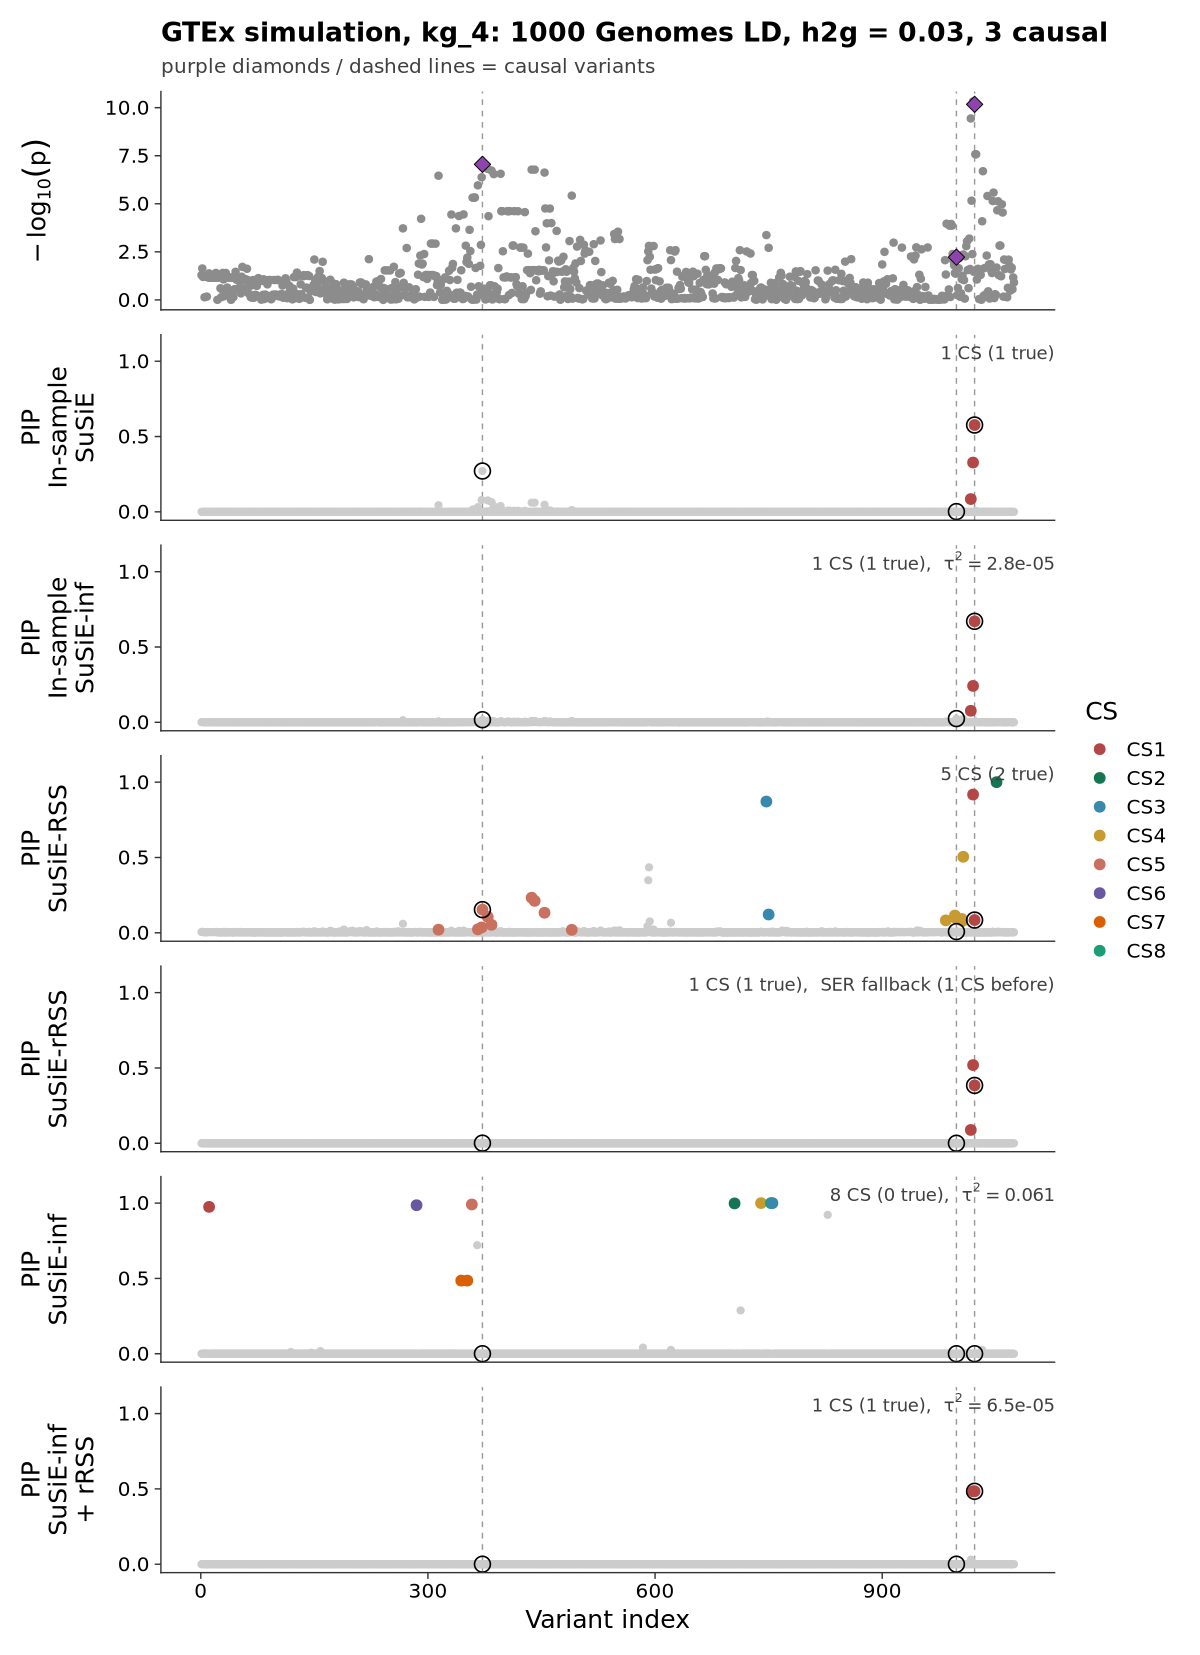

In [7]:
X <- 10; Y <- 2.4 + 1.9 * 6
options(repr.plot.width = X, repr.plot.height = Y)
p <- plot_example(c("insample", "insample_inf", "susie_rss", "susie_rrss", "susie_inf", "susie_inf_rrss"))
p
save_fig(p, "GTEx_SuSiE_inf_Example_kg4_All_Methods")

## In-sample SuSiE, SuSiE-inf, SuSiE-inf + rRSS

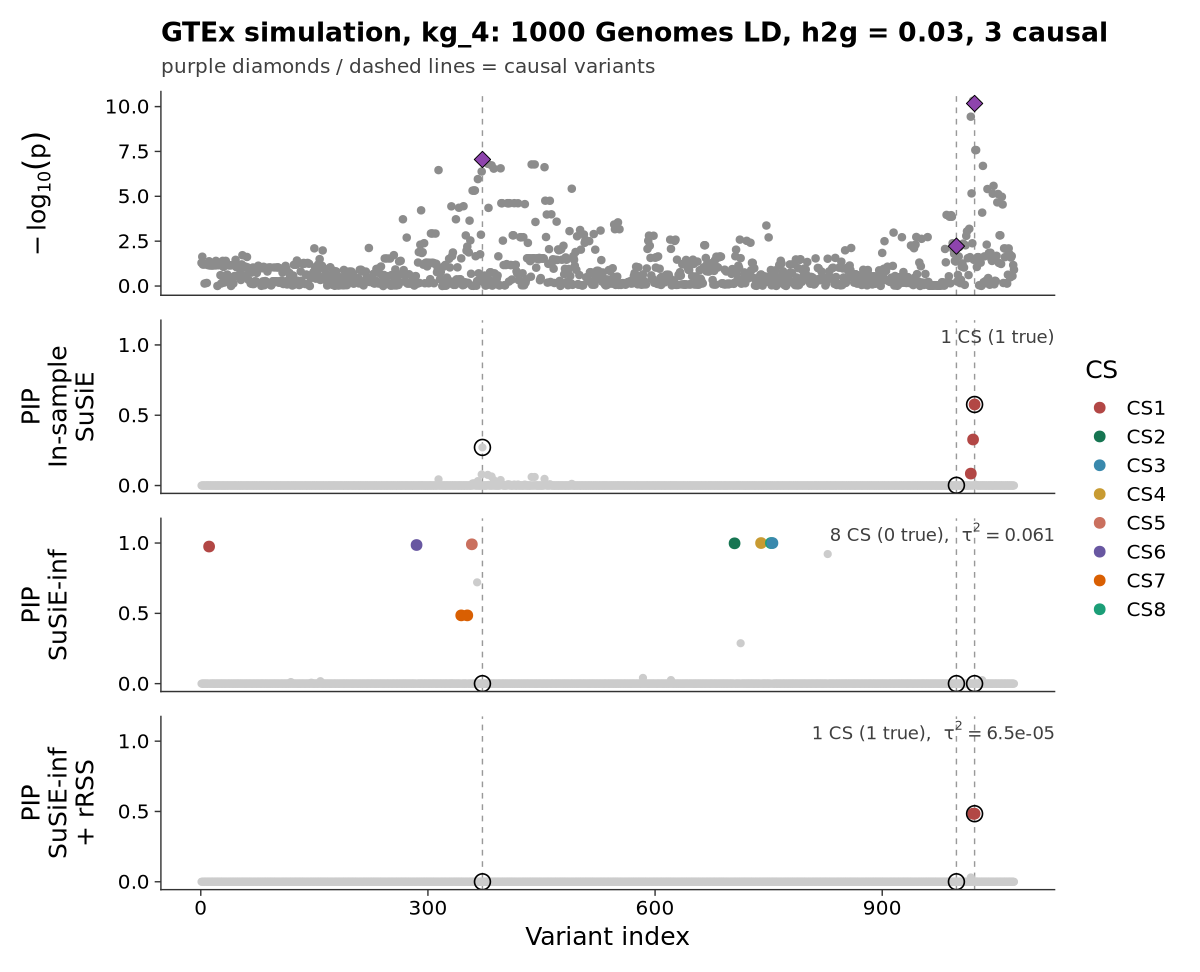

In [8]:
X <- 10; Y <- 2.4 + 1.9 * 3
options(repr.plot.width = X, repr.plot.height = Y)
p <- plot_example(c("insample", "susie_inf", "susie_inf_rrss"))
p
save_fig(p, "GTEx_SuSiE_inf_Example_kg4")